
# Data Preparation of the Heart Diagnoses file

In [113]:
import pandas as pd
import numpy as np
import seaborn as sns
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
from src.utils import data_understanding as du





heart_diagnoses_df = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")



## Data Cleaning

In [114]:
#drop columns with information not relevant for the analysis: free text columns, reports columns,unusefull columns
heart_diagnoses_df = heart_diagnoses_df.drop(columns=["CT", "MRI", "X-ray", "Ultrasound", "ECG", "CATH", "invasions", "reports","chief_complaint", "physical_exam","HPI","anchor_year","note_seq","note_type"])
heart_diagnoses_df_columns= du.get_cols(heart_diagnoses_df)
print("Columns in heart diagnoses dataset:",heart_diagnoses_df_columns) 

Columns in heart diagnoses dataset: ['note_id', 'subject_id', 'hadm_id', 'charttime', 'storetime', 'subject_id_dx', 'icd_code', 'long_title', 'gender', 'age', 'dod']


In [115]:
#Missing value analysis
#age and gender have missing values but they can be usfull for the analysis so we will keep them
#dod has many missing values can be  that the patient witout dod is alive or the data is missing, so is ambiguous, we will drop it
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["dod"])


In [116]:
#icd_code analysis: drop rows with rare icd_code (less then 30)
min_icd_count=30
icd_counts=heart_diagnoses_df['icd_code'].value_counts()
rare_icd_codes=icd_counts[icd_counts<min_icd_count].index
heart_diagnoses_df=heart_diagnoses_df[~heart_diagnoses_df['icd_code'].isin(rare_icd_codes)]
print("Icd_code more common:", heart_diagnoses_df['icd_code'].drop_duplicates())




Icd_code more common: 0      I50
1      I21
4      I35
6      I25
12     I48
17     I47
31     I31
33     I44
42     I33
46     I42
116    I30
195    I20
199    I49
524    I34
Name: icd_code, dtype: object


In [117]:
#drop columns that have info achieved in another coloumns 
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["note_id","subject_id_dx"])


In [118]:

#cleaning charttime column : drop the rows where there is an error between charttime and storetime
heart_diagnoses_df = heart_diagnoses_df[heart_diagnoses_df["charttime"] <= heart_diagnoses_df["storetime"]]
#for time analysis i choose to keep only the charttime column and drop the others
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["storetime"])


In [119]:
#fill missing values in age with the mean age for each icd_code
#heart_diagnoses_df["age"] = heart_diagnoses_df.groupby("icd_code")["age"].transform(lambda x: x.fillna(x.median()))
#cosa ho osservato: se sostituisco con media o mediana tutti i valori reali diventano ouliers perche 
#ci sono piu valori sostituiti che reali. provate ad applicare la trasformazione e poi fare boxplot


In [120]:
#final dataset analysis
print("Shape of heart diagnoses dataset:",)
heart_diagnoses_df.shape
print("Info of heart diagnoses dataset:")
heart_diagnoses_df.info()
heart_diagnoses_df_none=du.get_cols_with_none(heart_diagnoses_df)
print("Missing values in each column of heart diagnoses dataset:\n",heart_diagnoses_df_none)
print("Basic statistics of heart diagnoses dataset:")
du.get_basic_stats(heart_diagnoses_df)


Shape of heart diagnoses dataset:
Info of heart diagnoses dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 4814 entries, 0 to 4863
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   subject_id  4814 non-null   int64  
 1   hadm_id     4814 non-null   int64  
 2   charttime   4814 non-null   object 
 3   icd_code    4814 non-null   object 
 4   long_title  4814 non-null   object 
 5   gender      1345 non-null   object 
 6   age         1345 non-null   float64
dtypes: float64(1), int64(2), object(4)
memory usage: 300.9+ KB
Missing values in each column of heart diagnoses dataset:
 subject_id    False
hadm_id       False
charttime     False
icd_code      False
long_title    False
gender         True
age            True
dtype: bool
Basic statistics of heart diagnoses dataset:


,age
count,1345.000000
mean,69.066914
std,14.861162
min,22.000000
25%,60.000000
50%,70.000000
75%,81.000000
max,95.000000


In [121]:
#number of occurrences of each icd_code in the dataset
icd_code_counts = heart_diagnoses_df['icd_code'].value_counts()
print("Number of occurrences of each icd_code:\n", icd_code_counts)

Number of occurrences of each icd_code:
 icd_code
I50    1445
I21    1431
I25     642
I48     438
I35     231
I31     153
I47     130
I30      83
I44      69
I34      50
I33      38
I20      36
I49      35
I42      33
Name: count, dtype: int64


In [122]:
#Print the number of Female, Male, and the Total (F + M) with that ICD code
totals= du.get_ICD_groups(heart_diagnoses_df)
print(totals)


gender      F    M  total
icd_code                 
I20         8   10     18
I21       167  295    462
I25        46   92    138
I30        15   12     27
I31        30   22     52
I33         2    8     10
I34         4    2      6
I35        17   32     49
I42         4    6     10
I44        10    7     17
I47        13   19     32
I48        71   74    145
I49         7    6     13
I50       157  158    315


In [123]:
# mean and median age for each icd_code
icd_stats = heart_diagnoses_df.groupby('icd_code')['age'].agg(['mean', 'median']).reset_index()
icd_stats.columns = ['icd_code', 'mean_age', 'median_age']
print("Mean and median age for each ICD code:\n", icd_stats)

Mean and median age for each ICD code:
    icd_code   mean_age  median_age
0       I20  54.210526        60.0
1       I21  68.647679        69.5
2       I25  65.828571        66.0
3       I30  59.851852        59.0
4       I31  57.924528        57.0
5       I33  51.700000        59.0
6       I34  73.000000        71.0
7       I35  80.230769        83.0
8       I42  52.400000        48.5
9       I44  78.941176        84.0
10      I47  68.187500        69.5
11      I48  71.132450        71.0
12      I49  62.076923        64.0
13      I50  72.436950        75.0


<Axes: xlabel='icd_code', ylabel='Count'>

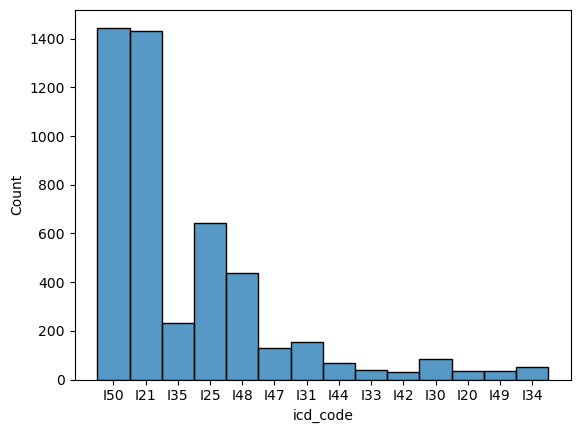

In [124]:
# visualize the new icd_code distribution
sns.histplot(heart_diagnoses_df, x="icd_code")


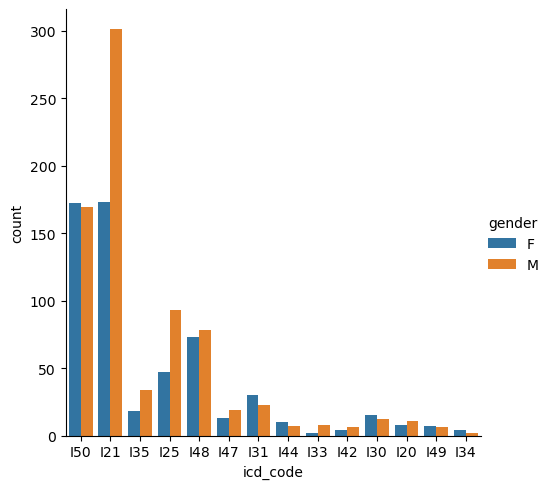

In [125]:
# visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

<Axes: xlabel='icd_code', ylabel='age'>

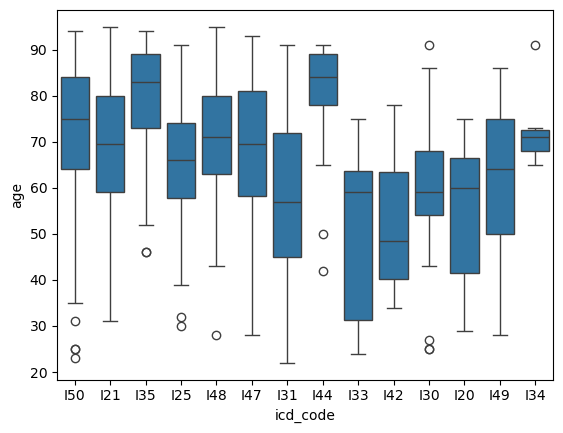

In [126]:
# visualize for each icd_code the age of the patient 
sns.boxplot(data=heart_diagnoses_df,x="icd_code",y="age")